# Bank Marketing — Term Deposit Subscription Prediction

**Steps covered:**
1. Import Libraries
2. Load Dataset
3. Understand the Dataset
4. Creating the Target Variable
5. Data Cleaning
6. Train/Test Split
7. Feature Preprocessing (Scaling & Encoding)
8. Saving Processed Data & Preprocessors
9. Train Multiple Models & Compare
10. Best Model Selection
11. Model Evaluation (Confusion Matrix, ROC & Accuracy)
12. Final Results Summary

## 1: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB

## 2: Load Dataset

In [ ]:
data_path = "../data/raw/bank-additional-full.csv"
df = pd.read_csv(data_path, sep=";")

print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3: Understand the Dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [6]:
print(df.isnull().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [7]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


## 4: Creating the Target Variable

In [8]:
# y is "yes"/"no", turn it into a binary target
df["target"] = (df["y"] == "yes").astype(int)
print(df["target"].value_counts())

target
0    36548
1     4640
Name: count, dtype: int64


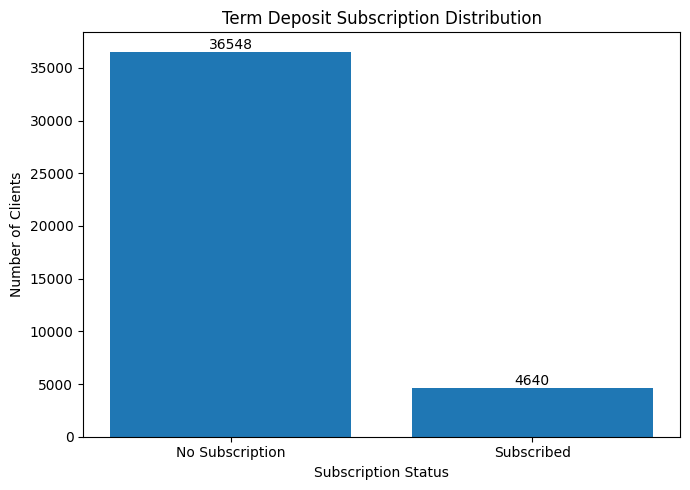

In [9]:
target_counts = df["target"].value_counts()
labels = ["No Subscription", "Subscribed"]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, target_counts.values)
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Clients")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
              str(int(bar.get_height())), ha="center", va="bottom")

plt.tight_layout()
plt.show()

## 5: Data Cleaning

In [10]:
# Remove exact duplicate rows
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dedup:", df.shape)

Duplicates: 12
Shape after dedup: (41176, 22)


In [11]:
# Several categorical columns use the literal string "unknown" instead of a
# real null. Treat "unknown" as missing so it gets imputed like any other gap.
unknown_cols = ["job", "marital", "education", "default", "housing", "loan"]
for col in unknown_cols:
    print(col, "->", (df[col] == "unknown").sum(), "unknown values")
    df[col] = df[col].replace("unknown", np.nan)

job -> 330 unknown values
marital -> 80 unknown values
education -> 1730 unknown values
default -> 8596 unknown values
housing -> 990 unknown values
loan -> 990 unknown values


In [12]:
# "duration" (last call length, in seconds) is only known AFTER a call ends,
# so it leaks the outcome and isn't available at prediction time in a real
# campaign. Drop it, along with the raw "y" column now that we have "target".
df = df.drop(["y", "duration"], axis=1)
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'target']


## 6: Train/Test Split

In [13]:
X = df.drop("target", axis=1)
y = df["target"]

print(X.shape, y.shape)

(41176, 19) (41176,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(32940, 19) (8236, 19)


## 7: Feature Preprocessing (Scaling & Encoding)

In [15]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns

print(list(num_cols))
print(list(cat_cols))

['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [16]:
for col in num_cols:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())

for col in cat_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[num_cols])
X_test_scaled = scaler.transform(X_test[num_cols])

In [18]:
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
X_train_encoded = ohe.fit_transform(X_train[cat_cols])
X_test_encoded = ohe.transform(X_test[cat_cols])

In [19]:
X_train_final = np.hstack((X_train_scaled, X_train_encoded))
X_test_final = np.hstack((X_test_scaled, X_test_encoded))

print(X_train_final.shape, X_test_final.shape)

(32940, 46) (8236, 46)


## 8: Saving Processed Data & Preprocessors

In [20]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
np.save("../data/processed/X_train_final.npy", X_train_final)
np.save("../data/processed/X_test_final.npy", X_test_final)
np.save("../data/processed/y_train.npy", y_train.values)
np.save("../data/processed/y_test.npy", y_test.values)

In [21]:
Path("../models").mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(ohe, "../models/ohe.pkl")

['../models/ohe.pkl']

## 9: Train Multiple Models & Compare

In [22]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
decision_tree_model = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight="balanced")
random_forest_model = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, class_weight="balanced"
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

In [23]:
svm_model = SVC(kernel="rbf", probability=True, random_state=42, class_weight="balanced")
knn_model = KNeighborsClassifier(n_neighbors=5)
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
)
adaboost_model = AdaBoostClassifier(n_estimators=100, random_state=42)
naive_bayes_model = GaussianNB()

models.update({
    "SVM": svm_model,
    "K-Nearest Neighbors": knn_model,
    "Gradient Boosting": gradient_boosting_model,
    "AdaBoost": adaboost_model,
    "Naive Bayes": naive_bayes_model
})

In [24]:
def evaluate_model(model, model_name):
    y_pred = model.predict(X_test_final)
    y_proba = model.predict_proba(X_test_final)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    print("\n" + model_name)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(roc_auc, 4))

    return {
        "Accuracy": accuracy, "Precision": precision, "Recall": recall,
        "F1": f1, "ROC_AUC": roc_auc, "fpr": fpr, "tpr": tpr
    }

In [25]:
metrics_results = {}
trained_models = {}
roc_data = {}

SVM_SAMPLE_SIZE = 8000  

for model_name, model in models.items():
    print("Training:", model_name)
    if model_name == "SVM" and len(X_train_final) > SVM_SAMPLE_SIZE:
        model.fit(X_train_final[:SVM_SAMPLE_SIZE], y_train[:SVM_SAMPLE_SIZE])
    else:
        model.fit(X_train_final, y_train)

    result = evaluate_model(model, model_name)

    metrics_results[model_name] = {
        "Accuracy": result["Accuracy"], "Precision": result["Precision"],
        "Recall": result["Recall"], "F1": result["F1"], "ROC_AUC": result["ROC_AUC"]
    }
    roc_data[model_name] = {"fpr": result["fpr"], "tpr": result["tpr"], "auc": result["ROC_AUC"]}
    trained_models[model_name] = model

Training: Logistic Regression

Logistic Regression
Accuracy : 0.831
Precision: 0.3602
Recall   : 0.6444
F1 Score : 0.4621
ROC-AUC  : 0.7994
Training: Decision Tree

Decision Tree
Accuracy : 0.8701
Precision: 0.4435
Recall   : 0.6002
F1 Score : 0.5101
ROC-AUC  : 0.7909
Training: Random Forest

Random Forest
Accuracy : 0.8593
Precision: 0.418
Recall   : 0.6347
F1 Score : 0.5041
ROC-AUC  : 0.8102
Training: SVM

SVM
Accuracy : 0.8494
Precision: 0.3953
Recall   : 0.6347
F1 Score : 0.4872
ROC-AUC  : 0.7861
Training: K-Nearest Neighbors

K-Nearest Neighbors
Accuracy : 0.8938
Precision: 0.5533
Recall   : 0.2963
F1 Score : 0.386
ROC-AUC  : 0.7412
Training: Gradient Boosting

Gradient Boosting
Accuracy : 0.9
Precision: 0.6576
Recall   : 0.2338
F1 Score : 0.345
ROC-AUC  : 0.8071
Training: AdaBoost

AdaBoost
Accuracy : 0.8993
Precision: 0.6868
Recall   : 0.1961
F1 Score : 0.3051
ROC-AUC  : 0.7968
Training: Naive Bayes

Naive Bayes
Accuracy : 0.8284
Precision: 0.3354
Recall   : 0.5323
F1 Score : 0.

In [26]:
results_df = pd.DataFrame(metrics_results).T
results_df = results_df.sort_values(by="F1", ascending=False)
print(results_df)

                     Accuracy  Precision    Recall        F1   ROC_AUC
Decision Tree        0.870083   0.443471  0.600216  0.510073  0.790908
Random Forest        0.859276   0.418027  0.634698  0.504065  0.810236
SVM                  0.849441   0.395302  0.634698  0.487179  0.786057
Logistic Regression  0.830986   0.360241  0.644397  0.462133  0.799373
Naive Bayes          0.828436   0.335370  0.532328  0.411495  0.773944
K-Nearest Neighbors  0.893759   0.553320  0.296336  0.385965  0.741152
Gradient Boosting    0.899951   0.657576  0.233836  0.344992  0.807085
AdaBoost             0.899344   0.686792  0.196121  0.305113  0.796841


## 10: Best Model Selection

In [27]:
best_model_name = results_df["F1"].idxmax()
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print(results_df.loc[best_model_name])

Best Model: Decision Tree
Accuracy     0.870083
Precision    0.443471
Recall       0.600216
F1           0.510073
ROC_AUC      0.790908
Name: Decision Tree, dtype: float64


In [28]:
joblib.dump(best_model, "../models/best_model.pkl")

['../models/best_model.pkl']

## 11: Model Evaluation (Confusion Matrix, ROC & Accuracy)

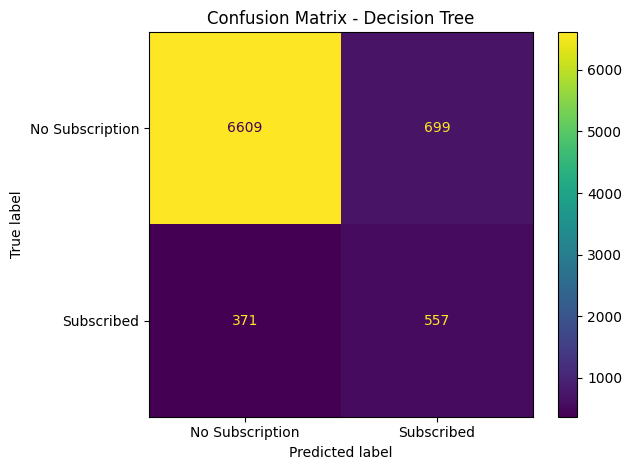

In [29]:
best_predictions = best_model.predict(X_test_final)

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["No Subscription", "Subscribed"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [30]:
Path("../outputs").mkdir(parents=True, exist_ok=True)

mismatched = X_test.copy()
mismatched["actual"] = y_test
mismatched["predicted"] = best_predictions

false_negatives = mismatched[(mismatched["actual"] == 1) & (mismatched["predicted"] == 0)]
false_positives = mismatched[(mismatched["actual"] == 0) & (mismatched["predicted"] == 1)]

false_negatives.to_csv("../outputs/false_negatives.csv", index=False)
false_positives.to_csv("../outputs/false_positives.csv", index=False)

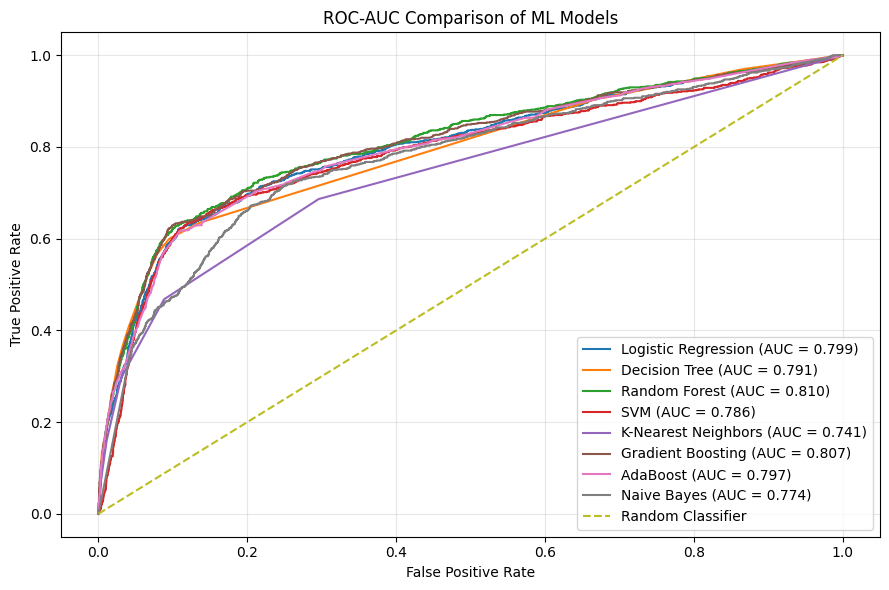

In [31]:
plt.figure(figsize=(9, 6))
for model_name, data in roc_data.items():
    plt.plot(data["fpr"], data["tpr"], label=f"{model_name} (AUC = {data['auc']:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Comparison of ML Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

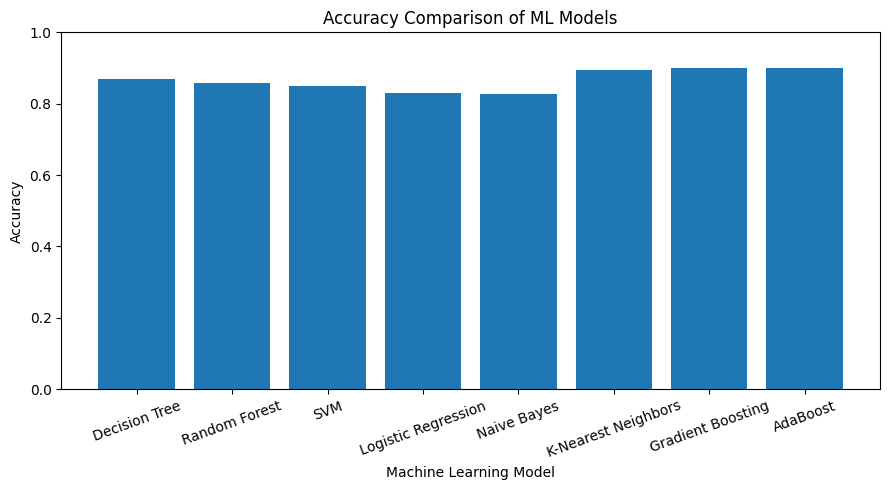

In [32]:
plt.figure(figsize=(9, 5))
plt.bar(results_df.index, results_df["Accuracy"])
plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [33]:
results_df.to_csv("../outputs/model_comparison.csv")

## 12: Final Results Summary

In [34]:
print("=" * 50)
print("FINAL MODEL RESULT")
print("=" * 50)
print("Best Model:", best_model_name)
print("Accuracy:", f"{results_df.loc[best_model_name, 'Accuracy'] * 100:.2f}%")
print("Precision:", f"{results_df.loc[best_model_name, 'Precision'] * 100:.2f}%")
print("Recall:", f"{results_df.loc[best_model_name, 'Recall'] * 100:.2f}%")
print("F1 Score:", f"{results_df.loc[best_model_name, 'F1'] * 100:.2f}%")
print("ROC-AUC:", f"{results_df.loc[best_model_name, 'ROC_AUC'] * 100:.2f}%")

FINAL MODEL RESULT
Best Model: Decision Tree
Accuracy: 87.01%
Precision: 44.35%
Recall: 60.02%
F1 Score: 51.01%
ROC-AUC: 79.09%
